In [26]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [27]:
df = pd.read_csv('Iris.csv')

In [28]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [29]:
df = df.iloc[:,1:]

In [30]:
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [31]:
from sklearn.preprocessing import LabelEncoder

In [32]:
encoder = LabelEncoder()

In [33]:
df['Species'] = encoder.fit_transform(df['Species'])

In [34]:
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [35]:
df = df[df['Species'] != 0][['SepalWidthCm','PetalLengthCm','Species']]

In [36]:
df.head()

,SepalWidthCm,PetalLengthCm,Species
50,3.2,4.7,1
51,3.2,4.5,1
52,3.1,4.9,1
53,2.3,4.0,1
54,2.8,4.6,1


In [37]:
import seaborn as sns
import matplotlib.pyplot as plt

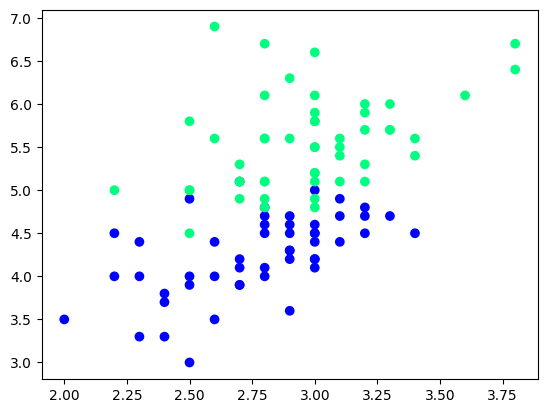

In [38]:
plt.scatter(df['SepalWidthCm'],df['PetalLengthCm'],c=df['Species'],cmap='winter')

In [39]:
df_train = df.iloc[:60,:].sample(10)
df_train

,SepalWidthCm,PetalLengthCm,Species
108,2.5,5.8,2
69,2.5,3.9,1
72,2.5,4.9,1
83,2.7,5.1,1
105,3.0,6.6,2
73,2.8,4.7,1
66,3.0,4.5,1
101,2.7,5.1,2
62,2.2,4.0,1
68,2.2,4.5,1


In [ ]:
# Taking only 10 rows for training
df = df.sample(100)
df_train = df.iloc[:60,:].sample(10) #training data
df_val = df.iloc[60:80,:].sample(5) # accuracy data
df_test = df.iloc[80:,:].sample(5) # prediction data

In [41]:
df_train

,SepalWidthCm,PetalLengthCm,Species
100,3.3,6.0,2
132,2.8,5.6,2
54,2.8,4.6,1
96,2.9,4.2,1
87,2.3,4.4,1
68,2.2,4.5,1
142,2.7,5.1,2
98,2.5,3.0,1
65,3.1,4.4,1
120,3.2,5.7,2


In [42]:
df_val

,SepalWidthCm,PetalLengthCm,Species
74,2.9,4.3,1
131,3.8,6.4,2
71,2.8,4.0,1
58,2.9,4.6,1
127,3.0,4.9,2


In [43]:
df_test

,SepalWidthCm,PetalLengthCm,Species
93,2.3,3.3,1
139,3.1,5.4,2
125,3.2,6.0,2
97,2.9,4.3,1
59,2.7,3.9,1


In [44]:
X_test = df_val.iloc[:,0:2].values
y_test = df_val.iloc[:,-1].values

In [45]:
y_test

array([1, 2, 1, 1, 2])

# Case 1 - Bagging

In [ ]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True) #replace true means same rows can be repeated in the sample

X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

df_bag

,SepalWidthCm,PetalLengthCm,Species
54,2.8,4.6,1
98,2.5,3.0,1
87,2.3,4.4,1
65,3.1,4.4,1
54,2.8,4.6,1
68,2.2,4.5,1
100,3.3,6.0,2
65,3.1,4.4,1


In [47]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from mlxtend.plotting import plot_decision_regions
from sklearn.metrics import accuracy_score

In [48]:
dt_bag1 = DecisionTreeClassifier()

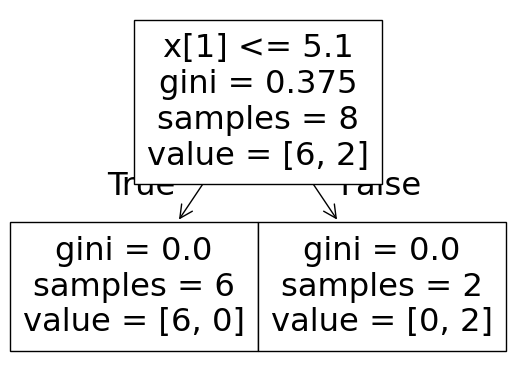

c:\Users\bilal\Desktop\MACHINE LEARNING\.venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


0.8


c:\Users\bilal\Desktop\MACHINE LEARNING\.venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


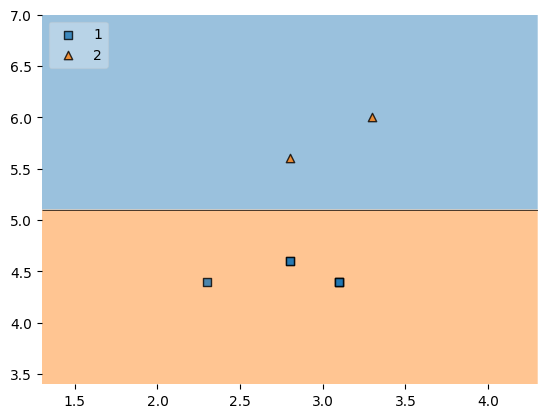

In [52]:
evaluate(dt_bag1,X,y)

In [53]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,SepalWidthCm,PetalLengthCm,Species
142,2.7,5.1,2
120,3.2,5.7,2
100,3.3,6.0,2
87,2.3,4.4,1
68,2.2,4.5,1
132,2.8,5.6,2
142,2.7,5.1,2
96,2.9,4.2,1


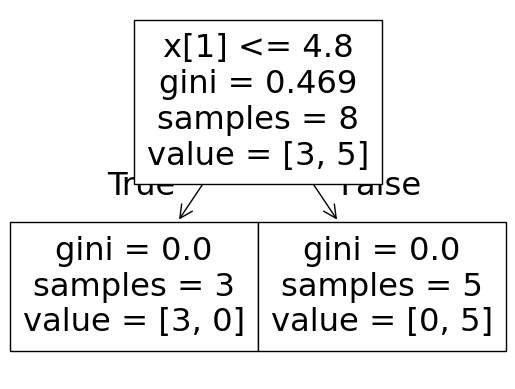

1.0


c:\Users\bilal\Desktop\MACHINE LEARNING\.venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Users\bilal\Desktop\MACHINE LEARNING\.venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


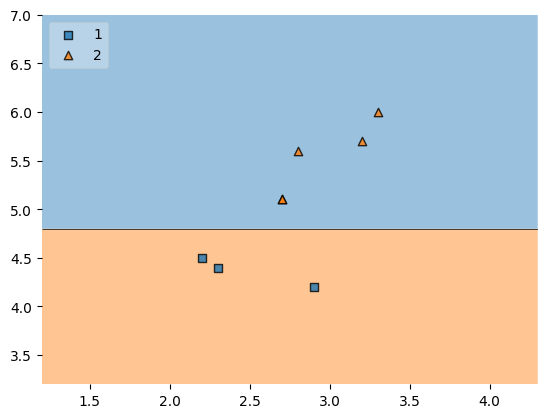

In [54]:
dt_bag2 = DecisionTreeClassifier()
evaluate(dt_bag2,X,y)

In [55]:
# Data for Tree 1
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,SepalWidthCm,PetalLengthCm,Species
142,2.7,5.1,2
54,2.8,4.6,1
120,3.2,5.7,2
98,2.5,3.0,1
142,2.7,5.1,2
87,2.3,4.4,1
142,2.7,5.1,2
68,2.2,4.5,1


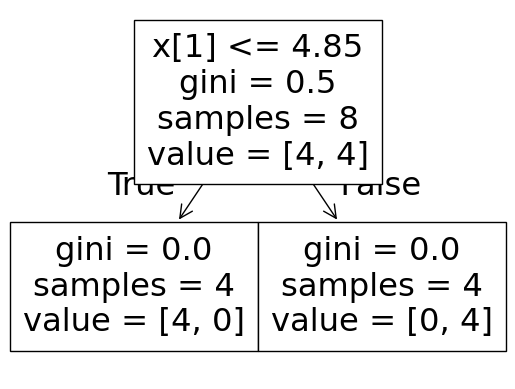

c:\Users\bilal\Desktop\MACHINE LEARNING\.venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Users\bilal\Desktop\MACHINE LEARNING\.venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


1.0


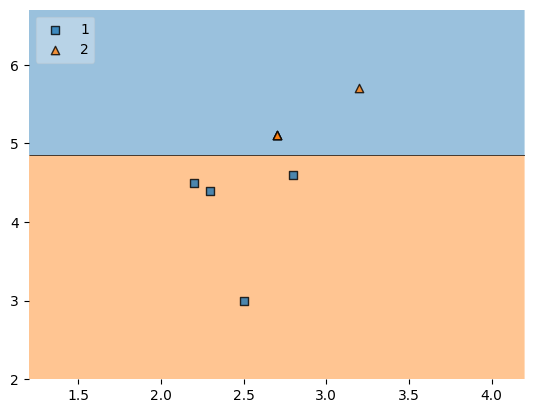

In [56]:
dt_bag3 = DecisionTreeClassifier()
evaluate(dt_bag3,X,y)

In [57]:
def evaluate(clf,X,y):
    clf.fit(X,y)
    plot_tree(clf)
    plt.show()
    plot_decision_regions(X.values, y.values, clf=clf, legend=2)
    y_pred = clf.predict(X_test)
    print(accuracy_score(y_test,y_pred))
    

## Predict

In [58]:
df_test

,SepalWidthCm,PetalLengthCm,Species
93,2.3,3.3,1
139,3.1,5.4,2
125,3.2,6.0,2
97,2.9,4.3,1
59,2.7,3.9,1


In [59]:
print("Predictor 1",dt_bag1.predict(np.array([2.2,5.0]).reshape(1,2)))
print("Predictor 2",dt_bag2.predict(np.array([2.2,5.0]).reshape(1,2)))
print("Predictor 3",dt_bag3.predict(np.array([2.2,5.0]).reshape(1,2)))

Predictor 1 [1]
Predictor 2 [2]
Predictor 3 [2]


c:\Users\bilal\Desktop\MACHINE LEARNING\.venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Users\bilal\Desktop\MACHINE LEARNING\.venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Users\bilal\Desktop\MACHINE LEARNING\.venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


# Pasting

In [60]:
# Row sampling without replacement
df_train

,SepalWidthCm,PetalLengthCm,Species
100,3.3,6.0,2
132,2.8,5.6,2
54,2.8,4.6,1
96,2.9,4.2,1
87,2.3,4.4,1
68,2.2,4.5,1
142,2.7,5.1,2
98,2.5,3.0,1
65,3.1,4.4,1
120,3.2,5.7,2


In [61]:
df_train.sample(8)

,SepalWidthCm,PetalLengthCm,Species
96,2.9,4.2,1
65,3.1,4.4,1
87,2.3,4.4,1
68,2.2,4.5,1
132,2.8,5.6,2
100,3.3,6.0,2
98,2.5,3.0,1
142,2.7,5.1,2


# Random Subspaces

In [67]:
df1 = pd.read_csv('Iris.csv')
df1 = df1.sample(10)

In [68]:
df1

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
107,108,7.3,2.9,6.3,1.8,Iris-virginica
62,63,6.0,2.2,4.0,1.0,Iris-versicolor
33,34,5.5,4.2,1.4,0.2,Iris-setosa
29,30,4.7,3.2,1.6,0.2,Iris-setosa
65,66,6.7,3.1,4.4,1.4,Iris-versicolor
55,56,5.7,2.8,4.5,1.3,Iris-versicolor
102,103,7.1,3.0,5.9,2.1,Iris-virginica
89,90,5.5,2.5,4.0,1.3,Iris-versicolor
23,24,5.1,3.3,1.7,0.5,Iris-setosa
5,6,5.4,3.9,1.7,0.4,Iris-setosa


In [69]:
df1.sample(2,replace=True,axis=1)

,Species,PetalLengthCm
107,Iris-virginica,6.3
62,Iris-versicolor,4.0
33,Iris-setosa,1.4
29,Iris-setosa,1.6
65,Iris-versicolor,4.4
55,Iris-versicolor,4.5
102,Iris-virginica,5.9
89,Iris-versicolor,4.0
23,Iris-setosa,1.7
5,Iris-setosa,1.7


# Random Patches

In [70]:
df1

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
107,108,7.3,2.9,6.3,1.8,Iris-virginica
62,63,6.0,2.2,4.0,1.0,Iris-versicolor
33,34,5.5,4.2,1.4,0.2,Iris-setosa
29,30,4.7,3.2,1.6,0.2,Iris-setosa
65,66,6.7,3.1,4.4,1.4,Iris-versicolor
55,56,5.7,2.8,4.5,1.3,Iris-versicolor
102,103,7.1,3.0,5.9,2.1,Iris-virginica
89,90,5.5,2.5,4.0,1.3,Iris-versicolor
23,24,5.1,3.3,1.7,0.5,Iris-setosa
5,6,5.4,3.9,1.7,0.4,Iris-setosa


In [71]:
df1.sample(8,replace=True).sample(2,replace=True,axis=1)

,Species,SepalLengthCm
33,Iris-setosa,5.5
89,Iris-versicolor,5.5
29,Iris-setosa,4.7
55,Iris-versicolor,5.7
33,Iris-setosa,5.5
62,Iris-versicolor,6.0
23,Iris-setosa,5.1
65,Iris-versicolor,6.7
